In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.pyplot import figure
import scipy
import statsmodels.api as sm
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
figsize = (14,8)
plt.rcParams["figure.figsize"] = figsize
import warnings
warnings.filterwarnings('ignore')
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.deterministic import DeterministicProcess
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# We start by loading our dataset and spliting data to train and test sets


In [2]:
df = pd.read_csv("eurostat_electricity_clean.csv")

In [3]:
df = df.rename(columns={'Time':'Date', 'Observation value':'Value'})
df['Date'] = pd.to_datetime(df["Date"])

In [4]:
df_train = df[:-24]
df_test = df[-24:]

In [5]:
train_ts = df_train['Value']
test_ts = df_test['Value']

# We start the data exploration with ploting the entire series

In [6]:
def plot_time_series(df,title='Electricity made available for final consumption since 2008',interval=1):
    ax = plt.gca()
    freq =f"{interval}YS"
    df.plot(x='Date', y='Value',ax=ax,title=title,x_compat=True)
    ax.set_xlim(df['Date'].min(), df['Date'].max())
    ax.xaxis.set_major_locator(mdates.YearLocator(base=interval, month=1, day=1))
    ax.set_xticks(pd.date_range(start=df['Date'].min(), end=df['Date'].max(), freq=freq))
    ax.tick_params(axis="both", which="minor", labelsize=1)
    ax.legend(['Available electricity'],loc='upper left',prop={'size': 12})
    plt.show()

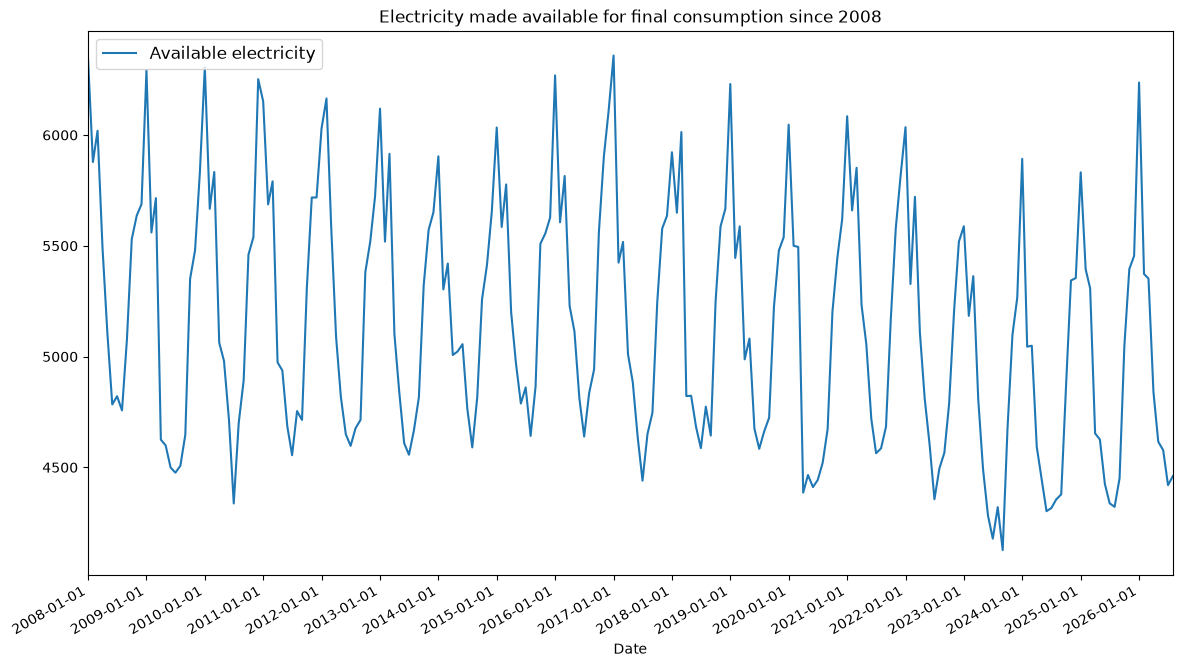

In [7]:
plot_time_series(df)

We see that the data are:
- seasonal with period of about 12 months where maximal value is typically reached during December/January and minimal during summer
- of slight downwards trend
- values vary from 4000 to around 6500

Since built in tsplot function is deprecated we do the tsplot of our own 

In [8]:
def tsplot(df, lags=36, title="Electricity available for final consumption", figsize=figsize, adf=True,interval=1):
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(3, 2)
    ts_ax   = fig.add_subplot(gs[0, :])
    acf_ax  = fig.add_subplot(gs[1, 0])
    pacf_ax = fig.add_subplot(gs[1, 1])
    hist_ax = fig.add_subplot(gs[2, 0])
    qq_ax   = fig.add_subplot(gs[2, 1])
    
    freq =f"{interval}YS"
    df.plot(x='Date', y='Value',ax=ts_ax,title=title,x_compat=True)
    ts_ax.set_xticks(pd.date_range(start=df['Date'].min(), end=df['Date'].max(),freq=freq))
    
    plot_acf(df['Value'], lags=lags, ax=acf_ax)
    plot_pacf(df['Value'], lags=lags, ax=pacf_ax, method="ywm")

    df['Value'].plot.hist(bins=20, ax=hist_ax, density=True, alpha=0.7)
    hist_ax.set_title("Histogram")

    stats.probplot(df['Value'], dist="norm", plot=qq_ax)
    qq_ax.set_title("Normal Q-Q")
    
    plt.tight_layout()

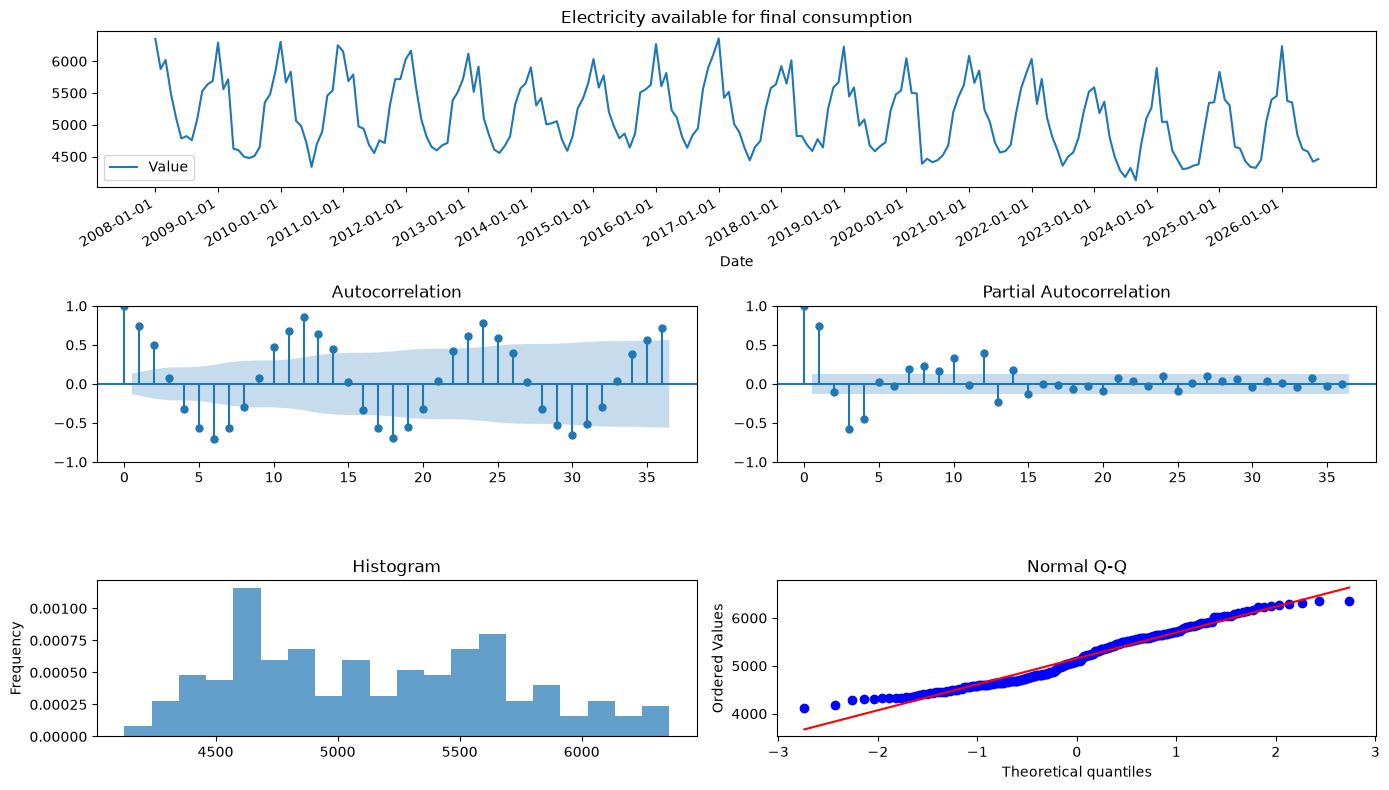

In [9]:
tsplot(df)

We see:
- autocorrelation resembles cosine function and repeat itself with period of 12 months
- the partial autocorrelation slowly converges to 0 after 15 lags 
- qq plot shows that data distribution has thick tales

# Finally, we decompose the data to seasonal elements 

In [57]:
def seasonal_decomp(ts):
    result = seasonal_decompose(ts, model='additive',extrapolate_trend='freq',period=12)
    result.plot()
    plt.show()
    return result

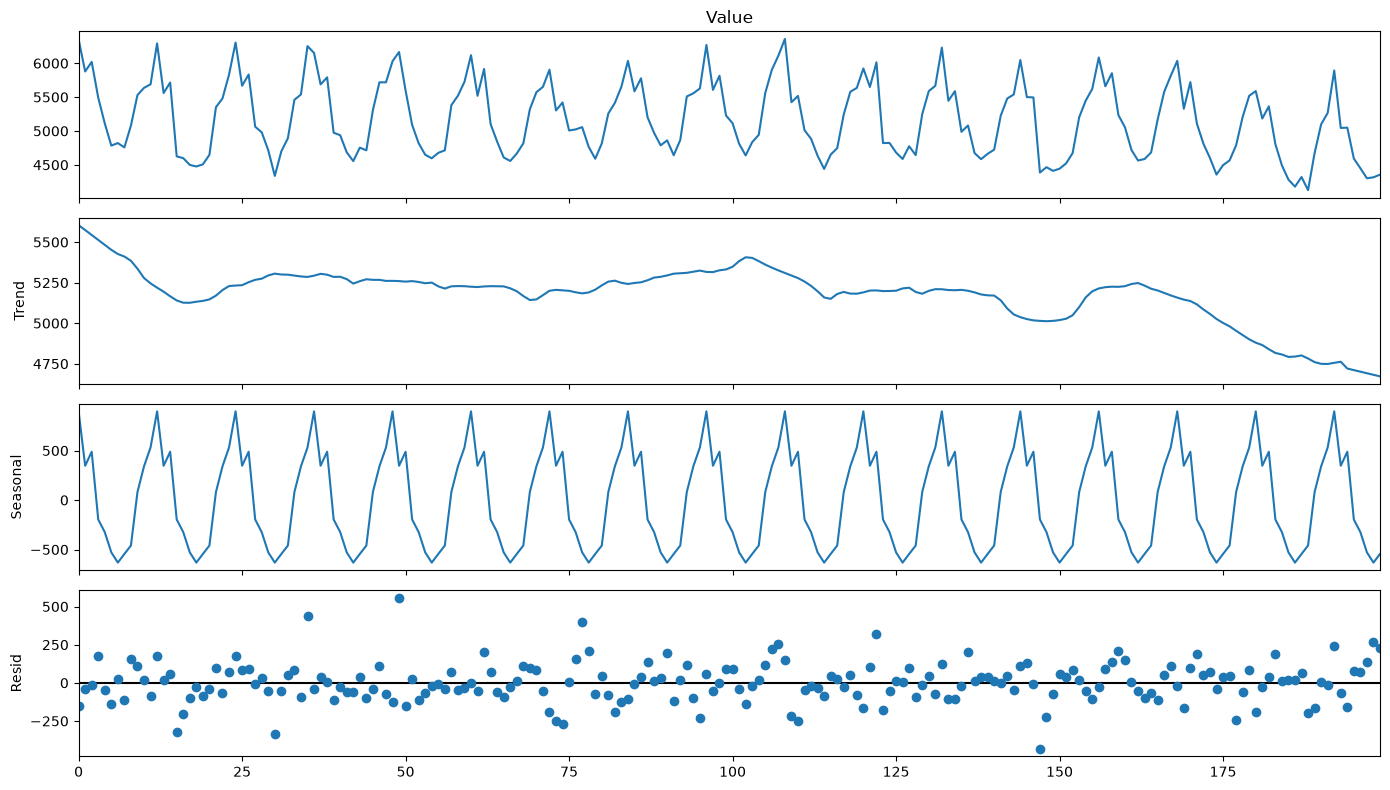

In [58]:
seasonal = seasonal_decomp(train_ts)

# We start model selection by implementing metrics for evaluation - RMSE and MSE


In [59]:
def rmse(y_true,y_pred):
    assert len(y_true) == len(y_pred)
    return np.sqrt(np.mean((y_true-y_pred)**2))

In [60]:
def mae(y_true,y_pred):
    assert len(y_true) == len(y_pred)
    return np.mean(np.abs(y_true-y_pred))

In [61]:
def print_metric(y_pred,y_true,dataset='train',model='AR'):
    print(f"The RMSE of prediction with {model} on {dataset} dataset is {rmse(y_pred,y_true):.2f}")
    print(f"The MAE of prediction with {model} on {dataset} dataset is {mae(y_pred,y_true):.2f}")

In [62]:
train_ts = df_train['Value']
test_ts = df_test['Value']

In [63]:
def plot_pred_interval(forecast, df_train, df_test, y_pred, title='model M',conf_int=None):

    conf_int = forecast.conf_int() if conf_int is None else conf_int

    train_dates = pd.to_datetime(df_train['Date'])
    test_dates = pd.to_datetime(df_test['Date'])
    

    
    fig, ax = plt.subplots()

    ax.plot(train_dates, train_ts, label='Train')
    ax.plot(test_dates, test_ts, label='Test', color='black')
    ax.plot(test_dates, y_pred.values, label='Forecast', color='red')

    ax.fill_between(
        test_dates,
        conf_int.iloc[:, 0].values,
        conf_int.iloc[:, 1].values,
        color='red',
        alpha=0.2,
        label='95% prediction interval'
    )

    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

    ax.legend()
    ax.set_title(title)
    ax.grid(False)
    fig.tight_layout()
    plt.show()

Lets build our first model. We use local linear deterministic trend with season 12 and 2 autoregressive steps. We assume the trend is near constant but since it has some longer parts where it diverges it we add 2 AR steps

# 1. model is Local linear deterministic trend with season of 12 lags and 2 autoregressive steps

In [64]:
%%time
model = sm.tsa.UnobservedComponents(
    train_ts,
    level='lldtrend',
    seasonal=12,
    autoregressive=2,
    #cycle=True
)

results = model.fit(disp=False)
burn = results.loglikelihood_burn
print(results.summary())

                               Unobserved Components Results                                
Dep. Variable:                                Value   No. Observations:                  200
Model:             local linear deterministic trend   Log Likelihood               -1220.044
                          + stochastic seasonal(12)   AIC                           2452.088
                                            + AR(2)   BIC                           2471.475
Date:                              Sat, 21 Nov 2026   HQIC                          2459.944
Time:                                      16:02:56                                         
Sample:                                           0                                         
                                              - 200                                         
Covariance Type:                                opg                                         
                       coef    std err          z      P>|z|      [0.0

In [65]:
forecast = results.get_forecast(steps=len(df_test))
y_pred = forecast.predicted_mean

**Ljung-Box Test for autocorrelation in the residuals**

In [66]:
resid = results.resid.iloc[13:]
print(acorr_ljungbox(resid, lags=[12, 24], return_df=True))

      lb_stat  lb_pvalue
12   3.530347   0.990501
24  16.922533   0.851947


The p-value is higher than 0.05 so we fail to reject $H_{0}$ - no autocorrelation appears in the residuals up to those lags

**Finally, we print out the MAE and RMSE**

In [67]:
print_metric(results.fittedvalues[burn:],train_ts[burn:],dataset='train',model='Local linear deterministic trend with season of 12 and 2 autoregressive step')

The RMSE of prediction with Local linear deterministic trend with season of 12 and 2 autoregressive step on train dataset is 169.05
The MAE of prediction with Local linear deterministic trend with season of 12 and 2 autoregressive step on train dataset is 123.62


In [68]:
print_metric(test_ts, y_pred,'test','Local linear deterministic trend with season of 12 and 2 autoregressive step')

The RMSE of prediction with Local linear deterministic trend with season of 12 and 2 autoregressive step on test dataset is 181.96
The MAE of prediction with Local linear deterministic trend with season of 12 and 2 autoregressive step on test dataset is 145.37


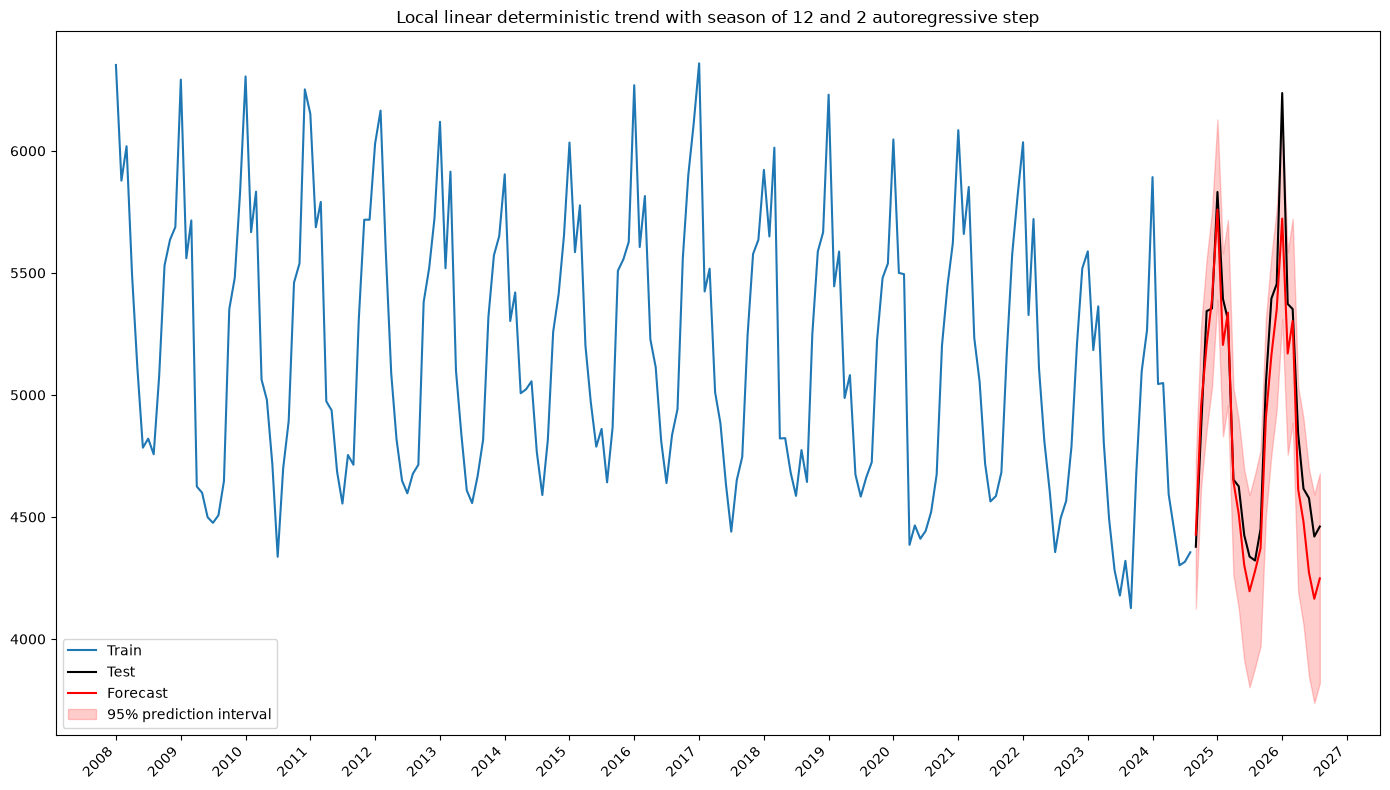

In [69]:
plot_pred_interval(forecast,df_train,df_test,y_pred, 'Local linear deterministic trend with season of 12 and 2 autoregressive step')

We see that this model behaves properly with relatively small error on both train and test data, but in latest, but graph shows that it is unable fit the latest season of the training data, the last peak is too high for this model.

Since this model reaches has problem of predicting the latest, we need to try something more suitable for long term predictions

Lets first try non-structural model of exponential smoothing to see how the latest season is going to behave. We expect that the season
and trend is multiplicatively related, hence we use Exponential Smoothing with multiplicative trend and season

# 2. model Exponential Smoothing with multiplicative trend and season + Holt-Winters forecast

In [23]:
%%time
model = ExponentialSmoothing(
    train_ts,
    trend='mul',               
    damped_trend=True,         
    seasonal='mul', 
    seasonal_periods=12,
    initialization_method='estimated',
)
results = model.fit()
print(results.summary())

                       ExponentialSmoothing Model Results                       
Dep. Variable:                    Value   No. Observations:                  200
Model:             ExponentialSmoothing   SSE                        4370025.354
Optimized:                         True   AIC                           2032.392
Trend:                   Multiplicative   BIC                           2088.464
Seasonal:                Multiplicative   AICC                          2036.615
Seasonal Periods:                    12   Date:                 Sat, 21 Nov 2026
Box-Cox:                          False   Time:                         15:56:49
Box-Cox Coeff.:                    None                                         
                          coeff                 code              optimized      
---------------------------------------------------------------------------------
smoothing_level               0.4105397                alpha                 True
smoothing_trend          

In [27]:
y_pred = results.forecast(steps=len(test_ts))

**Ljung-Box Test for autocorrelation in the residuals**

In [28]:
resid = results.resid.iloc[13:]
print(acorr_ljungbox(resid, lags=[12, 24], return_df=True))

      lb_stat  lb_pvalue
12  11.960749   0.448837
24  28.270885   0.248780


The result is very simmilar to the previous model. The p-value is higher than 0.05 so we fail to reject $H_{0}$ - no autocorrelation appears in the residuals up to lags 12 and 24.

**We look at our metrics**

In [29]:
print_metric(results.fittedvalues,train_ts,dataset='train',model='Exponential Smoothing')

The RMSE of prediction with Exponential Smoothing on train dataset is 147.82
The MAE of prediction with Exponential Smoothing on train dataset is 110.55


In [30]:
print_metric(y_pred,test_ts,dataset='test',model='Exponential Smoothing')

The RMSE of prediction with Exponential Smoothing on test dataset is 108.58
The MAE of prediction with Exponential Smoothing on test dataset is 76.01


**The error is lower in both datasets than in the previous case which is a good sign. Lets also look at the graph**

Since exponential smoothing doesnt have build-in confidence intervals we need to calculate them by ourselves by using  Holt-Winters forecast

In [33]:
sims = results.simulate(
    nsimulations=len(test_ts),
    repetitions=1000,
    error='mul',        
    random_errors='bootstrap',
)
lower = sims.quantile(0.025, axis=1)
upper = sims.quantile(0.975, axis=1)

In [34]:
intervals = pd.DataFrame(columns=['lower Value','upper Value'])
intervals['lower Value'] = lower
intervals['upper Value'] = upper

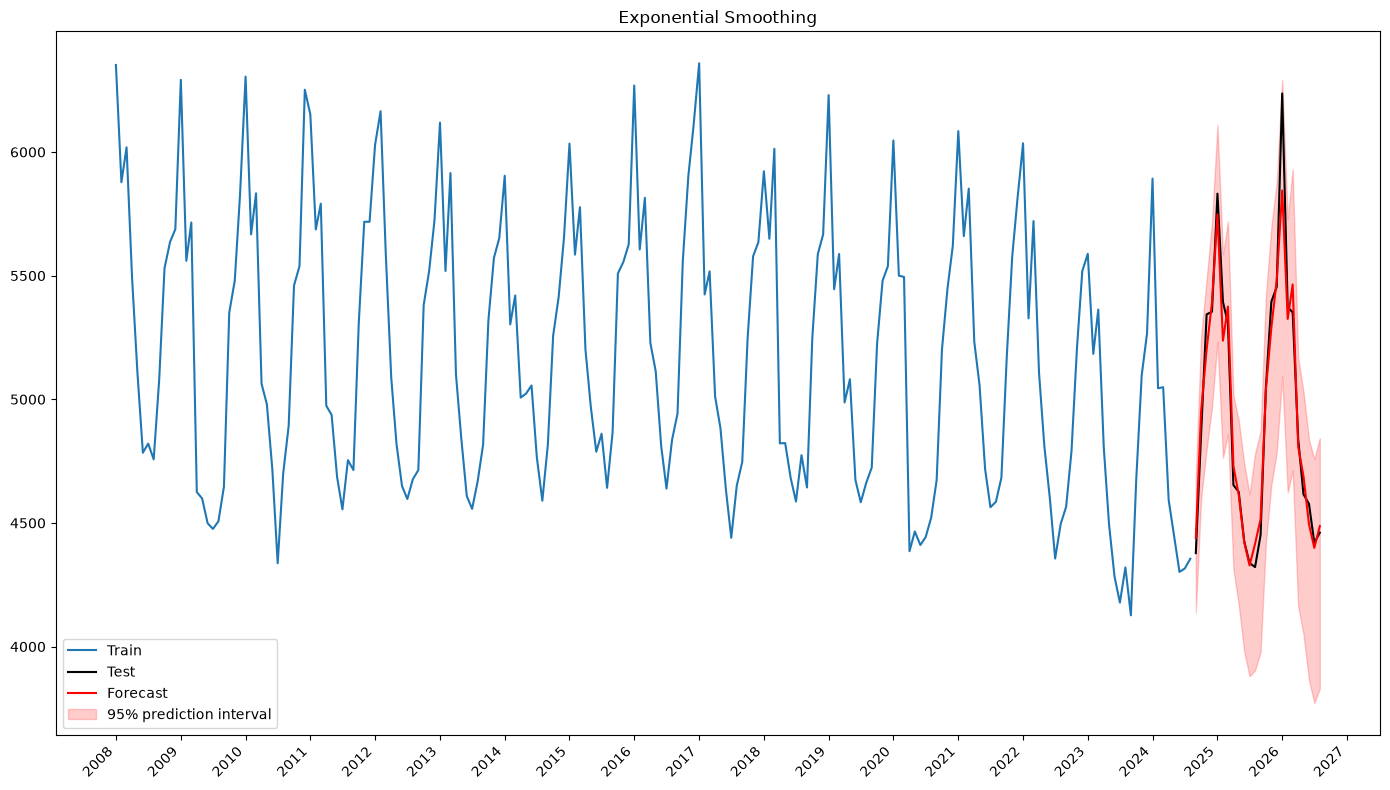

In [35]:
plot_pred_interval(forecast,df_train,df_test,y_pred, 'Exponential Smoothing',intervals)

This models error is lower than the first one on both test and train dataset. As we can observe in the graph it better captures the slope and level of the final season except for the peak which is an outlier.

In both our previous models, we measured time alongside the quality of the model with first model predicting in around 448 ms and the secound one in around 344 ms. In the last case, we are going to try simpler model to put the time down.

In the first structural model we used autoregressive of the 2nd order alongside the local trend. Lets now use AR(2) with Constant and linear time trend to see how would less sophisticated model act here.

# 3. model AR(2) with season and constant and linear time trend

In [70]:
%%time
dp = DeterministicProcess(df_train.index, constant=True, order=0, period=12)
X_train = dp.in_sample()
X_test  = dp.out_of_sample(steps=len(df_test)) 
reg=2
model = AutoReg(train_ts, lags=reg, trend="ct",seasonal=True,period=12)
results = model.fit()
print(results.summary())

                            AutoReg Model Results                             
Dep. Variable:                  Value   No. Observations:                  198
Model:               Seas. AutoReg(2)   Log Likelihood               -1267.107
Method:               Conditional MLE   S.D. of innovations            145.560
Date:                Sat, 21 Nov 2026   AIC                           2566.214
Time:                        16:03:58   BIC                           2618.826
Sample:                             2   HQIC                          2587.510
                                  200                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2555.2985    382.029      6.689      0.000    1806.535    3304.062
trend         -0.6975      0.221     -3.150      0.002      -1.131      -0.264
s(2,12)     -763.7460     55.829    -13.680      0.0

In [71]:
forecast = results.get_prediction(start=len(train_ts), end = len(test_ts) + len(train_ts))
y_pred = forecast.predicted_mean

**Ljung-Box Test for autocorrelation in the residuals**

In [72]:
resid = results.resid.iloc[13:]
print(acorr_ljungbox(resid, lags=[12, 24], return_df=True))

      lb_stat  lb_pvalue
12  10.331249   0.586925
24  27.152244   0.297407


Result: The p-value is higher than 0.05 so we fail to reject $H_{0}$ - no autocorrelation appears in the residuals up to lags 12 and 24.

**Lets look at the errors and the graph**

In [73]:
print_metric(results.fittedvalues,train_ts[reg:],'train','AR(2) + season')

The RMSE of prediction with AR(2) + season on train dataset is 145.56
The MAE of prediction with AR(2) + season on train dataset is 106.32


In [74]:
print_metric(y_pred[:-1], test_ts, 'test', 'AR(2) + season')

The RMSE of prediction with AR(2) + season on test dataset is 118.64
The MAE of prediction with AR(2) + season on test dataset is 89.18


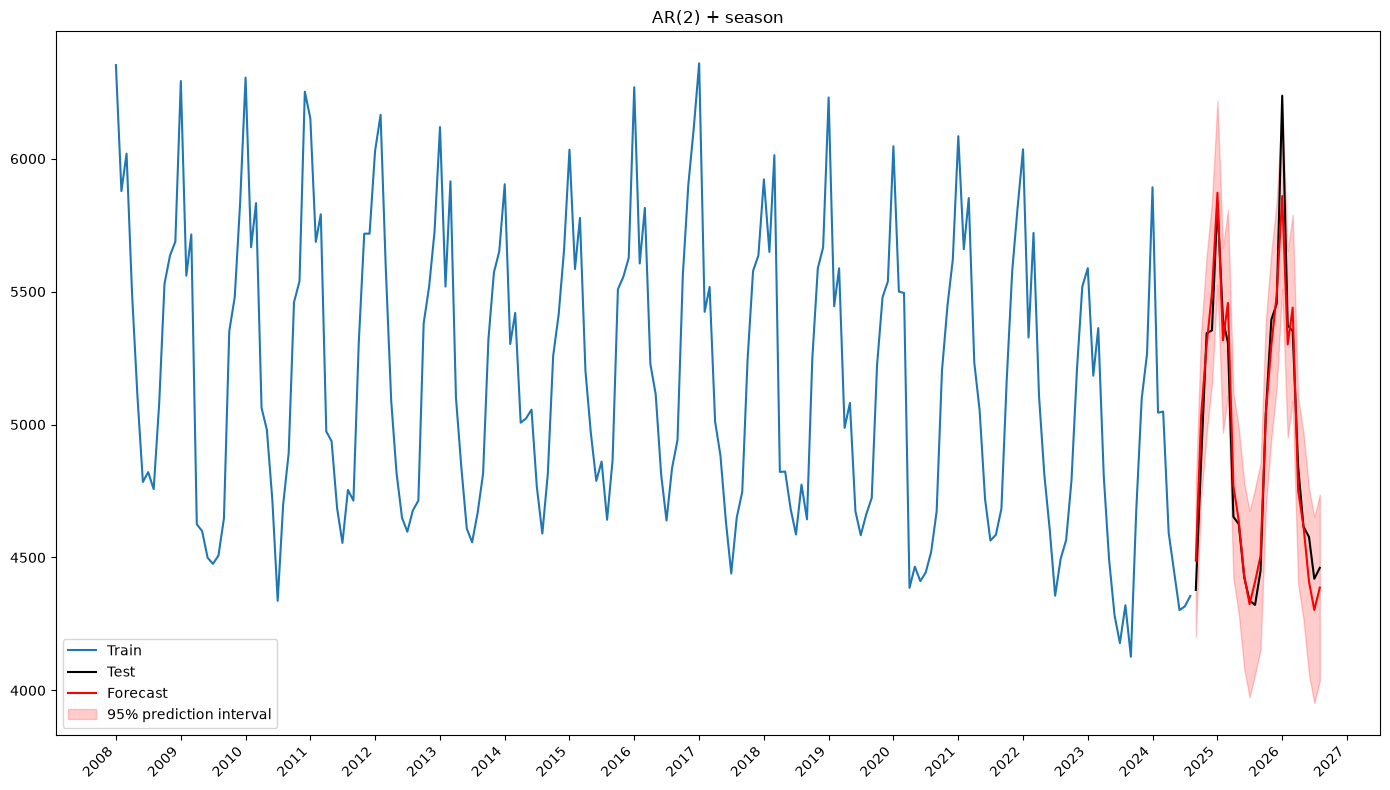

In [75]:
plot_pred_interval(forecast,df_train,df_test,y_pred[:-1],title="AR(2) + season",conf_int=forecast.conf_int()[:-1])

This model reaches a bit higher error than the previous one on both train and test dataset, but predicts everything in under 20 ms which is about 15 times faster than the previous ones. This would make it valuable in some use cases.

The downsite of this model is that it didnt capture the last peak in 95 % confidence interval so it has a problem predicting outliers.

Lets now use all of the experiences to build a final structural model. Lets drop the autogregressive part of the prediction and change the trend to smooth trend since the trend is slowly evolving. The cycle repeats after 12 months.

# 4. Smooth trend with season of 12

In [76]:
%%time
model = sm.tsa.UnobservedComponents(
    train_ts,
    level='strend',
    seasonal=12,
    freq_seasonal=[ {'period': 12, 'harmonics': 1}]
)

results = model.fit(disp=False)
burn = results.loglikelihood_burn
print(results.summary())

                                Unobserved Components Results                                
Dep. Variable:                                 Value   No. Observations:                  200
Model:                                  smooth trend   Log Likelihood               -1219.101
                           + stochastic seasonal(12)   AIC                           2446.201
                   + stochastic freq_seasonal(12(1))   BIC                           2459.083
Date:                               Sat, 21 Nov 2026   HQIC                          2451.422
Time:                                       16:04:16                                         
Sample:                                            0                                         
                                               - 200                                         
Covariance Type:                                 opg                                         
                                 coef    std err          z 

In [77]:
forecast = results.get_forecast(steps=len(df_test))
y_pred = forecast.predicted_mean

**Ljung-Box Test for autocorrelation in the residuals**

In [78]:
resid = results.resid.iloc[13:]
print(acorr_ljungbox(resid, lags=[12, 24], return_df=True))

      lb_stat  lb_pvalue
12  20.905003   0.051789
24  30.059430   0.182790


Result: The p-value is higher than 0.05 so we fail to reject $H_{0}$ - no autocorrelation appears in the residuals up to lags 12 and 24.

In [79]:
print_metric(results.fittedvalues[burn:],train_ts[burn:],dataset='train', model='Smooth trend with season of 12')

The RMSE of prediction with Smooth trend with season of 12 on train dataset is 178.94
The MAE of prediction with Smooth trend with season of 12 on train dataset is 135.23


In [80]:
print_metric(y_pred,test_ts,dataset='test',model='Smooth trend with season of 12')

The RMSE of prediction with Smooth trend with season of 12 on test dataset is 117.14
The MAE of prediction with Smooth trend with season of 12 on test dataset is 76.96


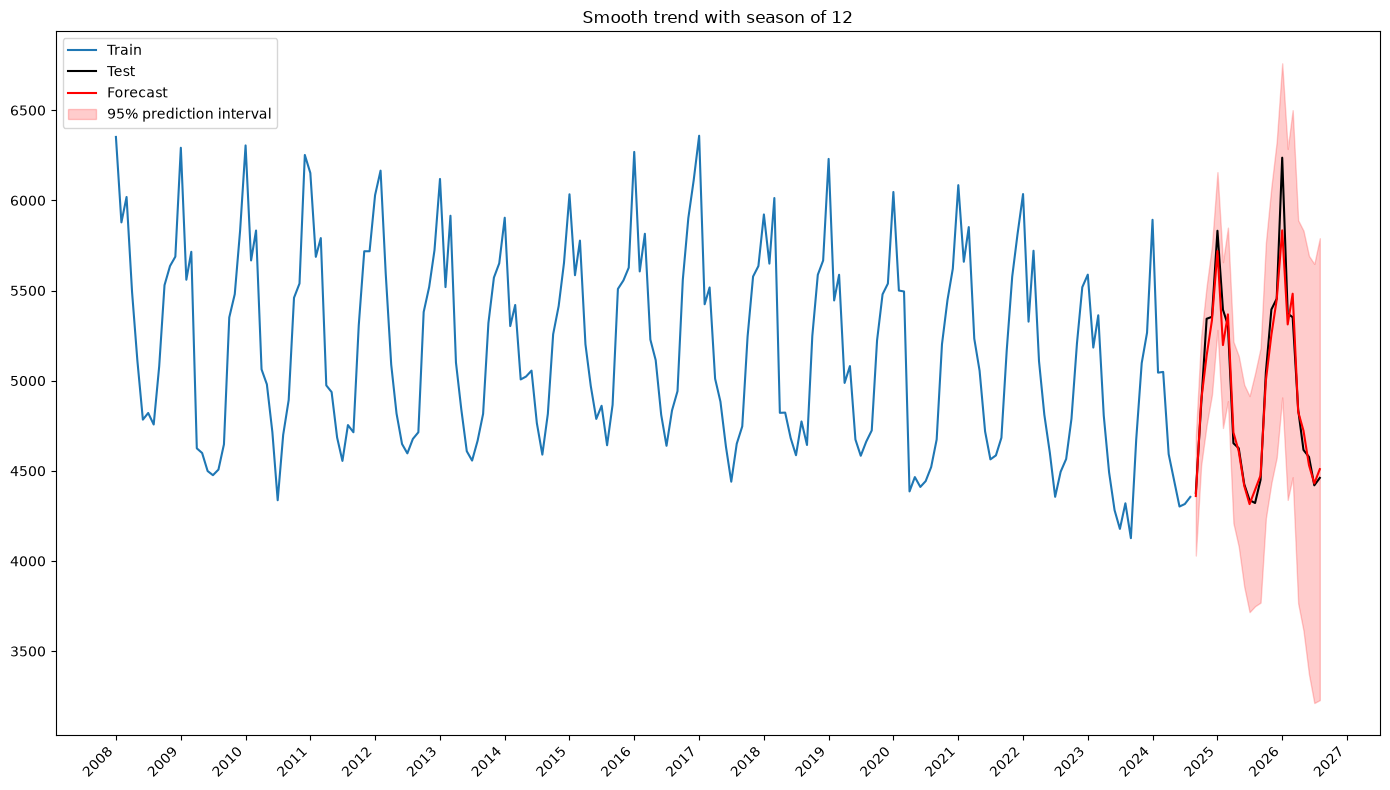

In [81]:
plot_pred_interval(forecast,df_train,df_test,y_pred, 'Smooth trend with season of 12')

This model reaches simmilar level of error as the Exponential smoothing one. The confidence interval is wider than the Local linear deterministic trend
which makes it less reliable. However the prediction itself is about 2 times faster than the first model.

# Final remarks: 
- All of the selected models reached fairly low error with Exponential Smoothing model being the best
- AR(2) with season and constant and linear time trend works the fastest without major quality loss 
- The quality of structural and unstructural models on this dataset is very simmilar